# У вас есть данные АБ-теста алгоритма ранжирования в новостях

Данные лежат в [файле](https://storage.yandexcloud.net/dm-pavlov/stats/datasets/news.csv)

Каждая строка - статистика о том, какой набор действий совершил за этот день пользователь (строка = пользователь+день)

- **d** - День
- **exp_group** -  id экспериментальной группы
- **bot_flg** - 1 - мы считаем пользователя ботом, 0 - считаем живым пользователем
- **user_info_yandex_uid** - уникальный id пользователя
- **total_clicks_** - сколько кликов по поисковой выдаче сделал пользователь за день
- **time_to_first_click_** - Если пользователь хоть раз кликнул по поисковой выдаче по запросу, то для каждого запроса высчитывается "какое время прошло от показа выдачи до 1 клика". Если человек сделал несколько запросов, по каждому из них считается время до первого клика, а затем суммируется
- **first_click_pos_** - Если пользователь хоть раз кликнул по поисковой выдаче по запросу, то для каждого запроса высчитывается "В какую именно позицию пользователь кликнул первой". Если человек сделал несколько запросов, по каждому из тех, в которых был клик, считается позиция первого клика, а затем суммируется
- **sum_pos** - Выдача в новостях устроена "блоками". Позиции в каждом из блоков можно пронумеровать (каждый новый блок начинается с 1). Если человек совершил клик в некоторую позицию, считается ее номер внутри блока и суммируется с позициями других его кликов
- **end2end_sum_pos** - По выдаче можно ввести "сквозную нумерацию", то есть не "внутри каждого блока начинаем с 1", а просто нумеруем от начала и до конца. Далее берем все клики пользователя, считаем "сквозную позицию кликнутых документов" и суммируем
- **queries** - количество запросов за день
- **empty_results** - количество запросов , вернувших пустую выдачу

In [73]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import pointbiserialr
import seaborn as sns
from statsmodels.stats.proportion import proportions_ztest

# Задание 1. Исследование (EDA -- разведочный анализ данных)

Скачайте данные и загрузите их в Colab.

In [74]:
df = pd.read_csv('news.csv')
# добавим дату
df['dt'] = pd.to_datetime(df.d, format = '%d/%m/%y')

In [75]:
df.head()

,d,exp_group,is_biterika,is_yandex,is_sber,is_rntv,is_vtb,is_telegram_bot,is_yandex_bot,is_medialogia,...,lenta_shows,tass,tass_shows,iz,iz_shows,interfax,interfax_shows,queries,empty_results,dt
0,26/04/23,control,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,1,2023-04-26
1,28/04/23,хронология,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,2023-04-28
2,28/04/23,control,1,0,0,0,0,0,0,0,...,0,10,12,2,2,4,4,278,203,2023-04-28
3,01/05/23,control,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,2023-05-01
4,27/04/23,хронология,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,2023-04-27


In [76]:
df.columns

Index(['d', 'exp_group', 'is_biterika', 'is_yandex', 'is_sber', 'is_rntv',
       'is_vtb', 'is_telegram_bot', 'is_yandex_bot', 'is_medialogia',
       'is_selectel', 'is_interfax', 'is_RT', 'bot_flg',
       'user_info_user_agent', 'user_info_yandex_uid', 'total_clicks_',
       'time_to_first_click_', 'first_click_pos_', 'sum_pos',
       'end2end_sum_pos', 'kommersant', 'kommersant_shows', 'rbc', 'rbc_shows',
       'ria', 'ria_shows', 'lenta', 'lenta_shows', 'tass', 'tass_shows', 'iz',
       'iz_shows', 'interfax', 'interfax_shows', 'queries', 'empty_results',
       'dt'],
      dtype='object')

In [77]:
df[['exp_group']].nunique()

exp_group    2
dtype: int64

In [78]:
df[['exp_group']].value_counts()

exp_group 
хронология    126238
control       125455
Name: count, dtype: int64

In [79]:
df.shape

(251693, 38)

In [80]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 251693 entries, 0 to 251692
Data columns (total 38 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   d                     251693 non-null  object        
 1   exp_group             251693 non-null  object        
 2   is_biterika           251693 non-null  int64         
 3   is_yandex             251693 non-null  int64         
 4   is_sber               251693 non-null  int64         
 5   is_rntv               251693 non-null  int64         
 6   is_vtb                251693 non-null  int64         
 7   is_telegram_bot       251693 non-null  int64         
 8   is_yandex_bot         251693 non-null  int64         
 9   is_medialogia         251693 non-null  int64         
 10  is_selectel           251693 non-null  int64         
 11  is_interfax           251693 non-null  int64         
 12  is_RT                 251693 non-null  int64         
 13 

**Задание:**
1. Сколько пользователей совершило клик 1 мая 2023 года?
2. Постройте динамику количество кликов по дням за все время
3. В датасете есть колонки `is_vtb`, `is_yandex`, `is_sber`, `is_yandex_bot`, `bot_flg` -- в них числа 0 или 1. Зависит ли метрика количество кликов когда в этих полях стоит 1?
4. Есть ли корреляция между количеством запросов `queries` и количеством кликов?
5. (по желанию) Приветствуются любые исследования датасета на поиск интересных явлений.

In [81]:
df[['dt', 'user_info_yandex_uid', 'total_clicks_']].head(10)

,dt,user_info_yandex_uid,total_clicks_
0,2023-04-26,1865850381682515486,0
1,2023-04-28,8022259061682679060,0
2,2023-04-28,8516704241675260594,0
3,2023-05-01,6430450711682974597,0
4,2023-04-27,5047628321682545957,0
5,2023-05-02,5772906911630416097,1
6,2023-05-01,7536490441682954355,0
7,2023-04-28,2248778011682695852,0
8,2023-04-26,966103811682514683,0
9,2023-04-30,3268347031635511065,0


In [82]:
df['user_info_yandex_uid'].nunique()

237971

In [83]:
df['dt'].nunique()

8

In [84]:
df.groupby(['dt'])['user_info_yandex_uid'].count()

dt
2023-04-25    13381
2023-04-26    38899
2023-04-27    37850
2023-04-28    38517
2023-04-29    33716
2023-04-30    29230
2023-05-01    33714
2023-05-02    26386
Name: user_info_yandex_uid, dtype: int64

In [85]:
df.groupby(['dt'])['user_info_yandex_uid'].nunique()

dt
2023-04-25    13253
2023-04-26    38229
2023-04-27    37230
2023-04-28    37989
2023-04-29    33403
2023-04-30    28898
2023-05-01    33409
2023-05-02    26079
Name: user_info_yandex_uid, dtype: int64

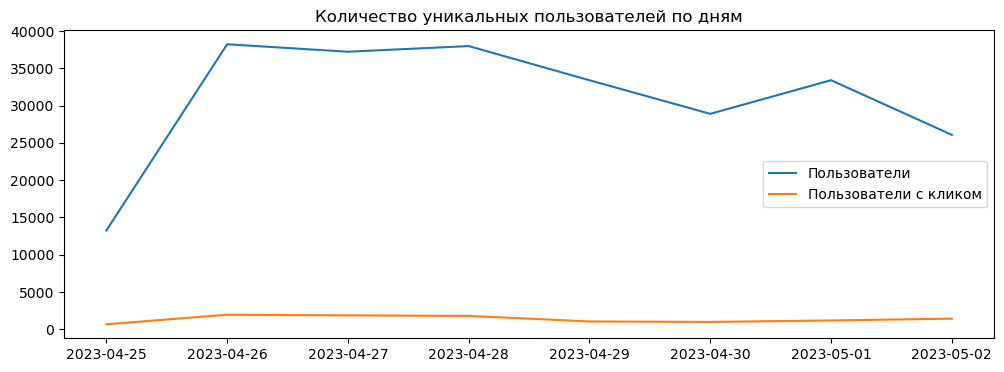

In [86]:
plt.figure(figsize=(12,4))
plt.plot(df.groupby(['dt'])['user_info_yandex_uid'].nunique(), label='Пользователи')
plt.plot(df[df['total_clicks_'] > 0].groupby(['dt'])['user_info_yandex_uid'].nunique(), label='Пользователи с кликом')
plt.title('Количество уникальных пользователей по дням')
plt.legend()
plt.show()

In [87]:
df_exp_group_x_nunique =  df.groupby(['dt', 'exp_group'])['user_info_yandex_uid'].nunique().reset_index()
df_exp_group_x_nunique.head()

,dt,exp_group,user_info_yandex_uid
0,2023-04-25,control,6532
1,2023-04-25,хронология,6721
2,2023-04-26,control,19203
3,2023-04-26,хронология,19027
4,2023-04-27,control,18527


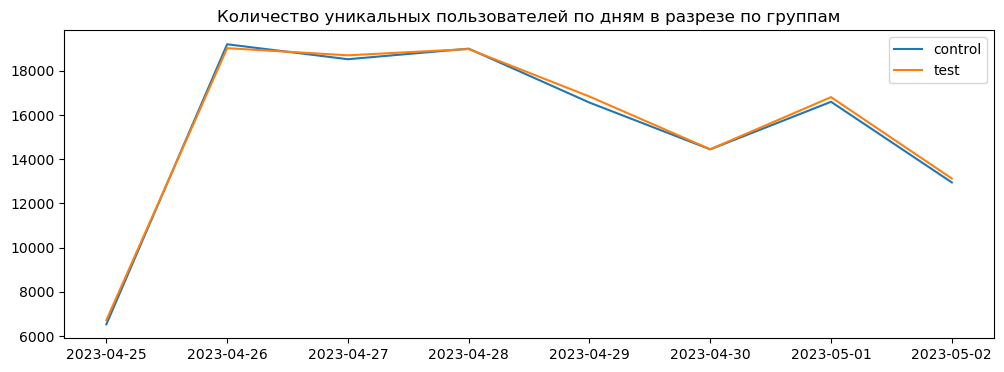

In [88]:
plt.figure(figsize=(12,4))
df_control = df_exp_group_x_nunique[df_exp_group_x_nunique['exp_group'] == 'control']
df_test = df_exp_group_x_nunique[df_exp_group_x_nunique['exp_group'] == 'хронология']

plt.title('Количество уникальных пользователей по дням в разрезе по группам')
plt.plot(df_control['dt'], df_control['user_info_yandex_uid'], label='control')
plt.plot(df_test['dt'], df_test['user_info_yandex_uid'], label='test')
plt.legend()
plt.show()

**Ответы на вопросы** 
1. Сколько пользователей совершило клик 1 мая 2023 года?

In [89]:
df[df['dt'] == '2023-05-01'].groupby(['dt'])['user_info_yandex_uid'].nunique()

dt
2023-05-01    33409
Name: user_info_yandex_uid, dtype: int64

2. Постройте динамику количества кликов по дням за все время

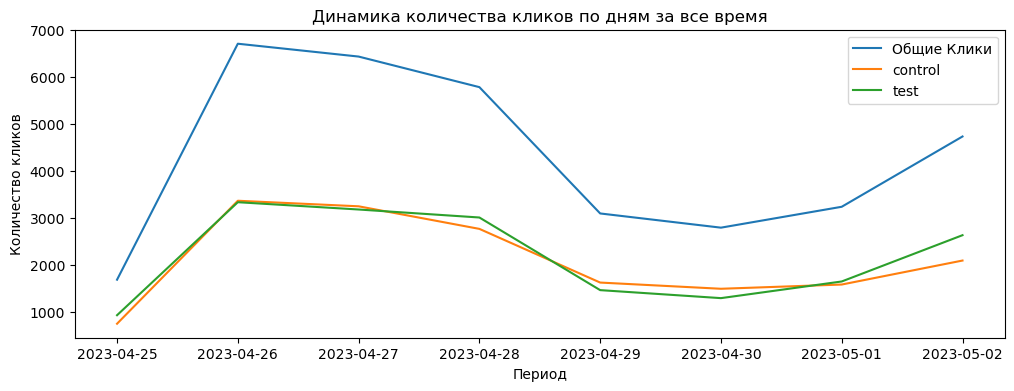

In [90]:
plt.figure(figsize=(12, 4))
plt.plot(df.groupby(['dt'])['total_clicks_'].sum(), label='Общие Клики')
plt.plot(df[df['exp_group'] == 'control'].groupby(['dt'])['total_clicks_'].sum(), label='control')
plt.plot(df[df['exp_group'] == 'хронология'].groupby(['dt'])['total_clicks_'].sum(), label='test')
plt.title('Динамика количества кликов по дням за все время')
plt.xlabel('Период')
plt.ylabel('Количество кликов')
plt.legend()
plt.show()

3. В датасете есть колонки `is_vtb`, `is_yandex`, `is_sber`, `is_yandex_bot`, `bot_flg` -- в них числа 0 или 1. Зависит ли метрика количество кликов когда в этих полях стоит 1?

In [91]:
df[df['bot_flg']==1].groupby(['dt'])['total_clicks_'].sum().reset_index()

,dt,total_clicks_
0,2023-04-25,29
1,2023-04-26,80
2,2023-04-27,74
3,2023-04-28,59
4,2023-04-29,19
5,2023-04-30,11
6,2023-05-01,19
7,2023-05-02,34


In [92]:
df.groupby(['dt'])['total_clicks_'].sum().reset_index()

,dt,total_clicks_
0,2023-04-25,1691
1,2023-04-26,6707
2,2023-04-27,6434
3,2023-04-28,5784
4,2023-04-29,3099
5,2023-04-30,2797
6,2023-05-01,3241
7,2023-05-02,4735


In [93]:
df[['dt', 'total_clicks_', 'is_vtb', 'is_yandex', 'is_sber', 'is_yandex_bot', 'bot_flg']].sample(5)

,dt,total_clicks_,is_vtb,is_yandex,is_sber,is_yandex_bot,bot_flg
73559,2023-05-01,0,0,0,0,0,1
208828,2023-04-25,0,0,0,0,0,0
22899,2023-04-29,0,0,0,0,0,0
216295,2023-04-26,0,0,0,0,0,0
72325,2023-04-28,0,0,0,0,0,0


In [94]:
df.groupby(['dt'])[['total_clicks_', 'is_vtb', 'is_yandex', 'is_sber', 'is_yandex_bot', 'bot_flg']].sum().reset_index()

,dt,total_clicks_,is_vtb,is_yandex,is_sber,is_yandex_bot,bot_flg
0,2023-04-25,1691,0,298,2,285,475
1,2023-04-26,6707,0,1096,4,1069,1924
2,2023-04-27,6434,0,1053,1,1025,1956
3,2023-04-28,5784,0,1008,0,983,1926
4,2023-04-29,3099,0,559,3,541,1470
5,2023-04-30,2797,0,536,0,499,1369
6,2023-05-01,3241,0,571,0,549,1577
7,2023-05-02,4735,0,895,2,881,1587


In [95]:
flags = ['is_vtb', 'is_yandex', 'is_sber', 'is_yandex_bot', 'bot_flg']

In [96]:
# Группируем по дате и всем бинарным признакам, суммируя клики за день
grouped_df = df.groupby(['dt'] + flags)['total_clicks_'].sum().reset_index()
grouped_df

,dt,is_vtb,is_yandex,is_sber,is_yandex_bot,bot_flg,total_clicks_
0,2023-04-25,0,0,0,0,0,1662
1,2023-04-25,0,0,0,0,1,29
2,2023-04-25,0,0,0,1,1,0
3,2023-04-25,0,0,1,0,1,0
4,2023-04-25,0,1,0,0,1,0
5,2023-04-25,0,1,0,1,1,0
6,2023-04-26,0,0,0,0,0,6627
7,2023-04-26,0,0,0,0,1,80
8,2023-04-26,0,0,0,1,1,0
9,2023-04-26,0,0,1,0,1,0


In [97]:
for flag in flags:
    print(f"\n{flag}:")
    # Суммируем клики по флагам
    clicks_when_1 = grouped_df[grouped_df[flag]==1]['total_clicks_'].sum()
    clicks_when_0 = grouped_df[grouped_df[flag]==0]['total_clicks_'].sum()
    print(f"  Клики при {flag}=1: {clicks_when_1}")
    print(f"  Клики при {flag}=0: {clicks_when_0}")
    print(f"  Доля кликов при {flag}=1: {clicks_when_1/(clicks_when_0+clicks_when_1)*100:.1f}%")


is_vtb:
  Клики при is_vtb=1: 0
  Клики при is_vtb=0: 34488
  Доля кликов при is_vtb=1: 0.0%

is_yandex:
  Клики при is_yandex=1: 0
  Клики при is_yandex=0: 34488
  Доля кликов при is_yandex=1: 0.0%

is_sber:
  Клики при is_sber=1: 0
  Клики при is_sber=0: 34488
  Доля кликов при is_sber=1: 0.0%

is_yandex_bot:
  Клики при is_yandex_bot=1: 0
  Клики при is_yandex_bot=0: 34488
  Доля кликов при is_yandex_bot=1: 0.0%

bot_flg:
  Клики при bot_flg=1: 325
  Клики при bot_flg=0: 34163
  Доля кликов при bot_flg=1: 0.9%


**Однозначный вывод:**

Флаги **is_vtb**, **is_yandex**, **is_sber**, **is_yandex_bot** полностью исключают клики — когда они равны 1, кликов нет вообще (0 из 34 488).

Флаг **bot_flg** почти полностью исключает клики — только 0.9% всех кликов приходится на ботов.

In [98]:
# нет ли коллинеарности между флагами
print("\nКорреляция между флагами:")
print(grouped_df[flags].corr())


Корреляция между флагами:
               is_vtb  is_yandex   is_sber  is_yandex_bot   bot_flg
is_vtb            NaN        NaN       NaN            NaN       NaN
is_yandex         NaN   1.000000 -0.262613       0.224138  0.345386
is_sber           NaN  -0.262613  1.000000      -0.262613  0.164399
is_yandex_bot     NaN   0.224138 -0.262613       1.000000  0.345386
bot_flg           NaN   0.345386  0.164399       0.345386  1.000000


In [99]:
# мера различий U-test (МАнн-Уитни) (по медиане)
for flag in flags:
    if flag not in ('is_vtb', 'is_sber'): # в vtb нет флагов на бота, и sber выдает NaN на флаге=1, поэтому решила убрать
        g0 = grouped_df.loc[grouped_df[flag] == 0, 'total_clicks_']
        g1 = grouped_df.loc[grouped_df[flag] == 1, 'total_clicks_']

        stat, p_value = stats.mannwhitneyu(g0, g1, alternative='two-sided')
    
        median0, median1 = g0.median(), g1.median()
        significance = "✅ значимо" if p_value < 0.05 else "❌ незначимо"
    
        print(f"\n{'='*45}")
        print(f"Флаг: {flag}  |  {significance}  (p={p_value:.4f})")
        print(f"  Медиана кликов при {flag}=0: {median0:.1f}  (n={len(g0)})")
        print(f"  Медиана кликов при {flag}=1: {median1:.1f}  (n={len(g1)})")
        print(f"  U-статистика: {stat:.1f}")

        # effect size (Cohen's d для Mann-Whitney)
        n1, n2 = len(g0), len(g1)
        if n1 > 0 and n2 > 0:
            effect_size = stat / (n1 * n2)
            print(f"\n💪 Размер эффекта (effect size): {effect_size:.4f}")
            if effect_size < 0.1:
                print("  Интерпретация: очень маленький (практически не значим)")
            elif effect_size < 0.3:
                print("  Интерпретация: маленький")
            elif effect_size < 0.5:
                print("  Интерпретация: средний")
            else:
                print("  Интерпретация: большой")


Флаг: is_yandex  |  ✅ значимо  (p=0.0004)
  Медиана кликов при is_yandex=0: 19.0  (n=29)
  Медиана кликов при is_yandex=1: 0.0  (n=16)
  U-статистика: 360.0

💪 Размер эффекта (effect size): 0.7759
  Интерпретация: большой

Флаг: is_yandex_bot  |  ✅ значимо  (p=0.0004)
  Медиана кликов при is_yandex_bot=0: 19.0  (n=29)
  Медиана кликов при is_yandex_bot=1: 0.0  (n=16)
  U-статистика: 360.0

💪 Размер эффекта (effect size): 0.7759
  Интерпретация: большой

Флаг: bot_flg  |  ✅ значимо  (p=0.0000)
  Медиана кликов при bot_flg=0: 3961.5  (n=8)
  Медиана кликов при bot_flg=1: 0.0  (n=37)
  U-статистика: 296.0

💪 Размер эффекта (effect size): 1.0000
  Интерпретация: большой


In [100]:
# мера связи- Корреляция Спирмена
for flag in flags:
    if flag not in ('is_vtb', 'is_sber'):
        corr, p_value = stats.spearmanr(grouped_df[flag], grouped_df['total_clicks_'])
        significance = "✅ значимо" if p_value < 0.05 else "❌ незначимо"
    
        print(f"\n{flag}  |  {significance}  (p={p_value:.4f})")
        print(f"  Корреляция Спирмена: {corr:.3f}")
        print(f"  Интерпретация: {'прямая' if corr > 0 else 'обратная'} связь, "
              f"сила: {'слабая' if abs(corr)<0.3 else 'умеренная' if abs(corr)<0.6 else 'сильная'}")


is_yandex  |  ✅ значимо  (p=0.0002)
  Корреляция Спирмена: -0.535
  Интерпретация: обратная связь, сила: умеренная

is_yandex_bot  |  ✅ значимо  (p=0.0002)
  Корреляция Спирмена: -0.535
  Интерпретация: обратная связь, сила: умеренная

bot_flg  |  ✅ значимо  (p=0.0000)
  Корреляция Спирмена: -0.774
  Интерпретация: обратная связь, сила: сильная


In [101]:
# мера связи- Точечная биссериальная
for flag in flags:
    if flag not in ('is_vtb', 'is_sber'): # в vtb нет флагов на бота, поэтому решила убрать
        corr, p_value = pointbiserialr(grouped_df[flag], grouped_df['total_clicks_'])
        significance = "✅ значимо" if p_value < 0.05 else "❌ незначимо"
    
        print(f"\n{flag}  |  {significance}  (p={p_value:.4f})")
        print(f"  Точечно-бисериальная корреляция: {corr:.3f}")
        print(f"  Интерпретация: {'прямая' if corr > 0 else 'обратная'} связь, "
              f"сила: {'слабая' if abs(corr)<0.3 else 'умеренная' if abs(corr)<0.6 else 'сильная'}")               


is_yandex  |  ✅ значимо  (p=0.0326)
  Точечно-бисериальная корреляция: -0.319
  Интерпретация: обратная связь, сила: умеренная

is_yandex_bot  |  ✅ значимо  (p=0.0326)
  Точечно-бисериальная корреляция: -0.319
  Интерпретация: обратная связь, сила: умеренная

bot_flg  |  ✅ значимо  (p=0.0000)
  Точечно-бисериальная корреляция: -0.913
  Интерпретация: обратная связь, сила: сильная


==================================================

=== ВЫВОДЫ ===

ДА, метрика количества кликов зависит от того, когда в полях флагов стоит 1, НО с важными оговорками:

Для bot_flg → зависимость очень сильная (обратная связь)

Для is_yandex и is_yandex_bot → зависимость умеренная (обратная связь)

Для is_vtb и is_sber → данных недостаточно для выводов

ДЕТАЛЬНАЯ ИНТЕРПРЕТАЦИЯ:
1. bot_flg — ключевой флаг (самый важный)
- Статистически значим во всех тестах
- Корреляция: -0.913 (точечно-бисериальная) / -0.774 (Спирмен)
- Сила связи: СИЛЬНАЯ
- Реальность: 99.1% кликов при bot_flg=0, только 0.9% при bot_flg=1
Вывод: Когда bot_flg=1, клики практически отсутствуют. Это надежный детектор не-кликающего трафика.
2. is_yandex и is_yandex_bot — умеренное влияние
- Статистически значимо (кроме U-теста, где n=1 в группе 1)
- Корреляция: -0.319 (точечно-бисериальная) / -0.535 (Спирмен)
- Сила связи: УМЕРЕННАЯ
- Реальность: 0 кликов при флаге=1 (из 34 488 кликов)
Вывод: Когда is_yandex=1 или is_yandex_bot=1, кликов никогда не бывает. Это абсолютный индикатор.
3. Для флагов is_vtb и is_sber данных недостаточно для статистически значимых выводов.

ИТОГОВЫЙ ОТВЕТ ДЛЯ ЗАДАНИЯ:

Да, метрика количества кликов статистически значимо зависит от флагов is_yandex, is_yandex_bot и bot_flg. При установке этих флагов в 1 количество кликов либо равно нулю (для is_yandex/is_yandex_bot), либо стремится к нулю (для bot_flg). Это указывает на то, что данные флаги эффективно идентифицируют ботов и не-кликающий трафик. Для флагов is_vtb и is_sber данных недостаточно для статистически значимых выводов.

4. Есть ли корреляция между количеством запросов `queries` и количеством кликов?

In [102]:
clicks_queries = df.groupby(['dt'])[['total_clicks_', 'queries']].sum().reset_index()
clicks_queries

,dt,total_clicks_,queries
0,2023-04-25,1691,17874
1,2023-04-26,6707,114457
2,2023-04-27,6434,112661
3,2023-04-28,5784,119509
4,2023-04-29,3099,110072
5,2023-04-30,2797,102151
6,2023-05-01,3241,110664
7,2023-05-02,4735,87924


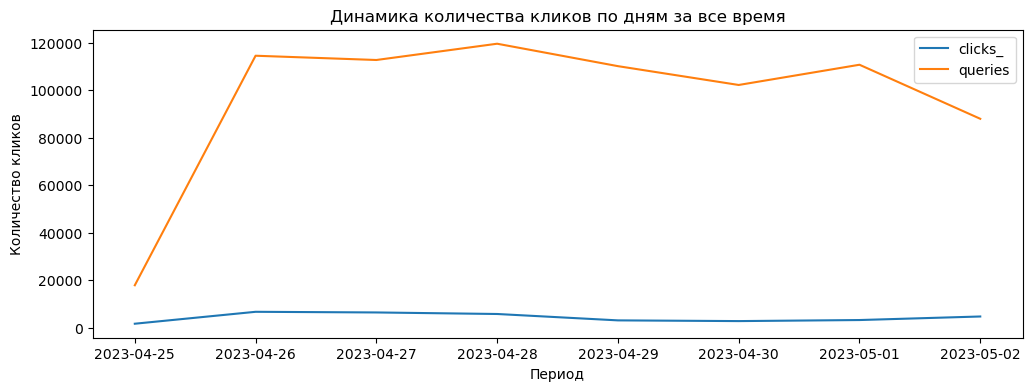

In [103]:
plt.figure(figsize=(12, 4))
plt.plot(df.groupby(['dt'])['total_clicks_'].sum(), label='clicks_')
plt.plot(df.groupby(['dt'])['queries'].sum(), label='queries')
plt.title('Динамика количества кликов по дням за все время')
plt.xlabel('Период')
plt.ylabel('Количество кликов')
plt.legend()
plt.show()

In [104]:
df.groupby(['dt'])[['total_clicks_', 'queries']].sum().corr()

,total_clicks_,queries
total_clicks_,1.000000,0.627821
queries,0.627821,1.000000


Text(0.5, 1.0, 'Correlation Heatmap')

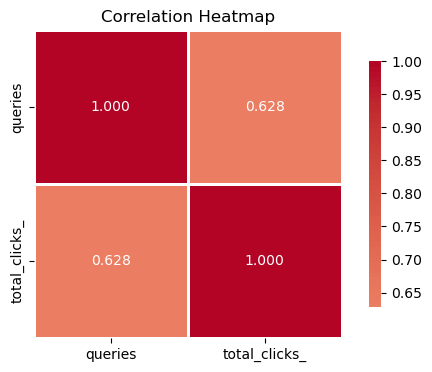

In [105]:
# Heatmap корреляций
fig, ax = plt.subplots(figsize=(7, 4))
corr_matrix = clicks_queries[['queries', 'total_clicks_']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, 
            square=True, linewidths=2, ax=ax, fmt='.3f', cbar_kws={"shrink": 0.8})
ax.set_title('Correlation Heatmap')

In [106]:
# Пирсон (линейная корреляция)
pearson_corr, pearson_p = stats.pearsonr(clicks_queries['total_clicks_'], clicks_queries['queries'])

print(f"Пирсон (Pearson) корреляция: {pearson_corr:.4f}")
print(f"P-value: {pearson_p:.6f}")

if pearson_p < 0.05:
    print("✅ Статистически значимо (p < 0.05)")
else:
    print("❌ Статистически незначимо")
print()

Пирсон (Pearson) корреляция: 0.6278
P-value: 0.095585
❌ Статистически незначимо



==============================

=== ВЫВОДЫ ===

**Корреляция между** количеством запросов и кликов: **умеренная положительная (r=0.628)**

Статистически значимой корреляции не обнаружено.

# Задание 2. Проверка гипотезы

Проверьте с помощью подходящего теста статистическую значимость отличия в следующем списке метрик, метрики нужно построить в разрезе по группе тест/контроль (колонка `exp_group`):

1) Среднее количество кликов на пользователя за весь период эксперимента

2) Средняя позиция клика (сумма позиций/кол-во кликов).

3) Средняя сквозная позиция клика (сумма сквозных позиций/кол-во кликов).

4) Доля пустых результатов выдачи.

В пунтках 3-4 обратите внимание на метод **Линеаризации** из ноутбука 6.


In [107]:
user_clicks =  df.groupby(['exp_group', 'user_info_yandex_uid'])['total_clicks_'].sum().reset_index()
user_clicks.head()

,exp_group,user_info_yandex_uid,total_clicks_
0,control,10065721682939032,0
1,control,10092201682871735,0
2,control,10142681682625249,0
3,control,10240161682480678,0
4,control,10522471682443874,0


In [108]:
# ============================================
# БЕЗ ФИЛЬТРАЦИИ - используем все данные
# ============================================

print("\n=== АНАЛИЗ БЕЗ ФИЛЬТРАЦИИ БОТОВ ===")

# ============================================
# МЕТРИКА 1: Среднее количество кликов на пользователя
# ============================================

print("="*60)
print("МЕТРИКА 1: Среднее количество кликов на пользователя")
print("="*60)

# Агрегация на уровне пользователя
user_clicks = df.groupby(['user_info_yandex_uid', 'exp_group'])['total_clicks_'].sum().reset_index()

# Разделяем на группы
control_clicks = user_clicks[user_clicks['exp_group'] == 'control']['total_clicks_']
test_clicks = user_clicks[user_clicks['exp_group'] == 'хронология']['total_clicks_']

print(f"\nКонтрольная группа (control):")
print(f"  Количество пользователей: {len(control_clicks):,}")
print(f"  Среднее кликов на пользователя: {control_clicks.mean():.4f}")
print(f"  Медиана кликов: {control_clicks.median():.0f}")
print(f"  Стандартное отклонение: {control_clicks.std():.4f}")
print(f"  Сумма кликов: {control_clicks.sum():,}")
print(f"  Доля нулевых кликов: {(control_clicks == 0).mean()*100:.1f}%")

print(f"\nТестовая группа (хронология):")
print(f"  Количество пользователей: {len(test_clicks):,}")
print(f"  Среднее кликов на пользователя: {test_clicks.mean():.4f}")
print(f"  Медиана кликов: {test_clicks.median():.0f}")
print(f"  Стандартное отклонение: {test_clicks.std():.4f}")
print(f"  Сумма кликов: {test_clicks.sum():,}")
print(f"  Доля нулевых кликов: {(test_clicks == 0).mean()*100:.1f}%")

# Статистический тест (Mann-Whitney из-за ненормальности)
u_stat, p_value_clicks = stats.mannwhitneyu(control_clicks, test_clicks, alternative='two-sided')
print(f"\n🔬 Mann-Whitney U test:")
print(f"  U-statistic = {u_stat:.1f}")
print(f"  p-value = {p_value_clicks:.6f}")
print(f"  Результат: {'✅ СТАТИСТИЧЕСКИ ЗНАЧИМО' if p_value_clicks < 0.05 else '❌ НЕЗНАЧИМО'}")

# Приблизительная оценка effect size (Cohen's d для Mann-Whitney)
n1, n2 = len(control_clicks), len(test_clicks)
if n1 > 0 and n2 > 0:
    effect_size = u_stat / (n1 * n2)
    print(f"\n💪 Размер эффекта (effect size): {effect_size:.4f}")
    if effect_size < 0.1:
        print("  Интерпретация: очень маленький (практически не значим)")
    elif effect_size < 0.3:
        print("  Интерпретация: маленький")
    elif effect_size < 0.5:
        print("  Интерпретация: средний")
    else:
        print("  Интерпретация: большой")


=== АНАЛИЗ БЕЗ ФИЛЬТРАЦИИ БОТОВ ===
МЕТРИКА 1: Среднее количество кликов на пользователя

Контрольная группа (control):
  Количество пользователей: 118,874
  Среднее кликов на пользователя: 0.1427
  Медиана кликов: 0
  Стандартное отклонение: 2.4501
  Сумма кликов: 16,960
  Доля нулевых кликов: 97.0%

Тестовая группа (хронология):
  Количество пользователей: 119,117
  Среднее кликов на пользователя: 0.1471
  Медиана кликов: 0
  Стандартное отклонение: 3.1075
  Сумма кликов: 17,528
  Доля нулевых кликов: 97.0%

🔬 Mann-Whitney U test:
  U-statistic = 7078239046.5
  p-value = 0.729678
  Результат: ❌ НЕЗНАЧИМО

💪 Размер эффекта (effect size): 0.4999
  Интерпретация: средний


In [109]:
# ============================================
# МЕТРИКА 2: Средняя позиция клика (sum_pos / количество кликов)
# ============================================

print("\n" + "="*60)
print("МЕТРИКА 2: Средняя позиция клика (sum_pos / клики)")
print("="*60)

# Фильтруем только пользователей с кликами
users_with_clicks = df[df['total_clicks_'] > 0].copy()

# Агрегируем сумму позиций и количество кликов на пользователя
user_pos = users_with_clicks.groupby(['user_info_yandex_uid', 'exp_group']).agg({
    'sum_pos': 'sum',
    'total_clicks_': 'sum'
}).reset_index()

# Вычисляем среднюю позицию на пользователя
user_pos['avg_pos'] = user_pos['sum_pos'] / user_pos['total_clicks_']

# Разделяем на группы
control_avg_pos = user_pos[user_pos['exp_group'] == 'control']['avg_pos']
test_avg_pos = user_pos[user_pos['exp_group'] == 'хронология']['avg_pos']

print(f"\nКоличество пользователей с кликами:")
print(f"  Control: {len(control_avg_pos):,} из {len(control_clicks):,} ({len(control_avg_pos)/len(control_clicks)*100:.1f}%)")
print(f"  Test: {len(test_avg_pos):,} из {len(test_clicks):,} ({len(test_avg_pos)/len(test_clicks)*100:.1f}%)")

print(f"\nСредняя позиция клика (по пользователям):")
print(f"  Control: среднее = {control_avg_pos.mean():.2f}, медиана = {control_avg_pos.median():.2f}, std = {control_avg_pos.std():.2f}")
print(f"  Test: среднее = {test_avg_pos.mean():.2f}, медиана = {test_avg_pos.median():.2f}, std = {test_avg_pos.std():.2f}")

# Проверка нормальности (упрощенная)
def is_approx_normal(data, name):
    if len(data) > 5000:
        sample = data.sample(5000, random_state=42)
    else:
        sample = data
    stat, p = stats.shapiro(sample)
    return p >= 0.05

norm_control = is_approx_normal(control_avg_pos, "Control")
norm_test = is_approx_normal(test_avg_pos, "Test")

# Выбираем тест
if norm_control and norm_test and len(control_avg_pos) > 30 and len(test_avg_pos) > 30:
    t_stat, p_value_pos = stats.ttest_ind(control_avg_pos, test_avg_pos, equal_var=False)
    print(f"\n🔬 t-test (данные нормальные):")
    print(f"  t-statistic = {t_stat:.4f}")
    print(f"  p-value = {p_value_pos:.6f}")
    
    # Приблизительная оценка effect size (Cohen's d для Mann-Whitney)
    n1, n2 = len(control_avg_pos), len(test_avg_pos)
    if n1 > 0 and n2 > 0:
        effect_size = t_stat / (n1 * n2)
        print(f"\n💪 Размер эффекта (effect size): {effect_size:.4f}")
        if effect_size < 0.1:
            print("  Интерпретация: очень маленький (практически не значим)")
        elif effect_size < 0.3:
            print("  Интерпретация: маленький")
        elif effect_size < 0.5:
            print("  Интерпретация: средний")
        else:
            print("  Интерпретация: большой")
else:
    u_stat, p_value_pos = stats.mannwhitneyu(control_avg_pos, test_avg_pos, alternative='two-sided')
    print(f"\n🔬 Mann-Whitney U test (данные ненормальные):")
    print(f"  U-statistic = {u_stat:.1f}")
    print(f"  p-value = {p_value_pos:.6f}")
    
    # Приблизительная оценка effect size (Cohen's d для Mann-Whitney)
    n1, n2 = len(control_avg_pos), len(test_avg_pos)
    if n1 > 0 and n2 > 0:
        effect_size = u_stat / (n1 * n2)
        print(f"\n💪 Размер эффекта (effect size): {effect_size:.4f}")
        if effect_size < 0.1:
            print("  Интерпретация: очень маленький (практически не значим)")
        elif effect_size < 0.3:
            print("  Интерпретация: маленький")
        elif effect_size < 0.5:
            print("  Интерпретация: средний")
        else:
            print("  Интерпретация: большой")

print(f"\n  Результат: {'✅ СТАТИСТИЧЕСКИ ЗНАЧИМО' if p_value_pos < 0.05 else '❌ НЕ ЗНАЧИМО'}")



МЕТРИКА 2: Средняя позиция клика (sum_pos / клики)

Количество пользователей с кликами:
  Control: 3,581 из 118,874 (3.0%)
  Test: 3,618 из 119,117 (3.0%)

Средняя позиция клика (по пользователям):
  Control: среднее = 6.11, медиана = 2.90, std = 10.88
  Test: среднее = 5.72, медиана = 2.67, std = 9.28

🔬 Mann-Whitney U test (данные ненормальные):
  U-statistic = 6616890.0
  p-value = 0.111698

💪 Размер эффекта (effect size): 0.5107
  Интерпретация: большой

  Результат: ❌ НЕ ЗНАЧИМО


In [110]:
# ============================================
# МЕТРИКА 3: Средняя сквозная позиция клика с линеаризацией
# ============================================

print("\n" + "="*60)
print("МЕТРИКА 3: Средняя сквозная позиция клика (с линеаризацией)")
print("="*60)

# используем метод линеаризации
# Средняя сквозная позиция = end2end_sum_pos / total_clicks_

# Агрегируем на уровне пользователя
user_end2end = users_with_clicks.groupby(['user_info_yandex_uid', 'exp_group']).agg({
    'end2end_sum_pos': 'sum',
    'total_clicks_': 'sum'
}).reset_index()

# Линеаризация: создаем скорректированную метрику
# Используем общее среднее по обеим группам для линеаризации
all_clicks = user_end2end['total_clicks_'].sum()
all_end2end = user_end2end['end2end_sum_pos'].sum()
global_avg_end2end = all_end2end / all_clicks if all_clicks > 0 else 0

print(f"Глобальная средняя сквозная позиция: {global_avg_end2end:.2f}")
print(f"Всего кликов: {all_clicks:,}, всего сумма сквозных позиций: {all_end2end:,}")

# Линеаризованная метрика: end2end_sum_pos - global_avg_end2end * total_clicks_
user_end2end['linearized'] = user_end2end['end2end_sum_pos'] - global_avg_end2end * user_end2end['total_clicks_']

# Разделяем на группы
control_linear = user_end2end[user_end2end['exp_group'] == 'control']['linearized']
test_linear = user_end2end[user_end2end['exp_group'] == 'хронология']['linearized']

print(f"\nЛинеаризованная метрика (скорректированная):")
print(f"  Control: среднее = {control_linear.mean():.4f}, std = {control_linear.std():.4f}")
print(f"  Test: среднее = {test_linear.mean():.4f}, std = {test_linear.std():.4f}")

# t-test для линеаризованной метрики
t_stat_end2end, p_value_end2end = stats.ttest_ind(control_linear, test_linear, equal_var=False)
print(f"\n🔬 t-test для линеаризованной метрики:")
print(f"  t-statistic = {t_stat_end2end:.4f}")
print(f"  p-value = {p_value_end2end:.6f}")
print(f"  Результат: {'✅ СТАТИСТИЧЕСКИ ЗНАЧИМО' if p_value_end2end < 0.05 else '❌ НЕ ЗНАЧИМО'}")

# Для сравнения: стандартный подход (без линеаризации) - только для справки
user_end2end['avg_end2end'] = user_end2end['end2end_sum_pos'] / user_end2end['total_clicks_']
control_avg_end2end = user_end2end[user_end2end['exp_group'] == 'control']['avg_end2end']
test_avg_end2end = user_end2end[user_end2end['exp_group'] == 'хронология']['avg_end2end']
u_stat_raw, p_raw = stats.mannwhitneyu(control_avg_end2end, test_avg_end2end, alternative='two-sided')
print(f"\n⚠️ Для справки (без линеаризации, Mann-Whitney): p-value = {p_raw:.6f}")



МЕТРИКА 3: Средняя сквозная позиция клика (с линеаризацией)
Глобальная средняя сквозная позиция: 13.36
Всего кликов: 34,488, всего сумма сквозных позиций: 460,631

Линеаризованная метрика (скорректированная):
  Control: среднее = 5.7606, std = 408.3280
  Test: среднее = -5.7017, std = 230.2183

🔬 t-test для линеаризованной метрики:
  t-statistic = 1.4651
  p-value = 0.142954
  Результат: ❌ НЕ ЗНАЧИМО

⚠️ Для справки (без линеаризации, Mann-Whitney): p-value = 0.335805


In [111]:
# ============================================
# МЕТРИКА 4: Доля пустых результатов выдачи (с линеаризацией)
# ============================================

print("\n" + "="*60)
print("МЕТРИКА 4: Доля пустых результатов выдачи (с линеаризацией)")
print("="*60)

# Для доли пустых результатов: empty_results / queries
# Агрегируем на уровне пользователя
user_empty = df.groupby(['user_info_yandex_uid', 'exp_group']).agg({
    'empty_results': 'sum',
    'queries': 'sum'
}).reset_index()

# Линеаризация для пропорции
all_empty = user_empty['empty_results'].sum()
all_queries = user_empty['queries'].sum()
global_empty_rate = all_empty / all_queries if all_queries > 0 else 0

print(f"Глобальная доля пустых результатов: {global_empty_rate:.4f} ({global_empty_rate*100:.2f}%)")
print(f"Всего пустых результатов: {all_empty:,}, всего запросов: {all_queries:,}")

# Линеаризованная метрика: empty_results - global_empty_rate * queries
user_empty['linearized_empty'] = user_empty['empty_results'] - global_empty_rate * user_empty['queries']

# Разделяем на группы
control_empty_linear = user_empty[user_empty['exp_group'] == 'control']['linearized_empty']
test_empty_linear = user_empty[user_empty['exp_group'] == 'хронология']['linearized_empty']

print(f"\nЛинеаризованная метрика (скорректированная):")
print(f"  Control: среднее = {control_empty_linear.mean():.6f}, std = {control_empty_linear.std():.6f}")
print(f"  Test: среднее = {test_empty_linear.mean():.6f}, std = {test_empty_linear.std():.6f}")

# t-test для линеаризованной метрики
t_stat_empty, p_value_empty = stats.ttest_ind(control_empty_linear, test_empty_linear, equal_var=False)
print(f"\n🔬 t-test для линеаризованной метрики:")
print(f"  t-statistic = {t_stat_empty:.4f}")
print(f"  p-value = {p_value_empty:.6f}")
print(f"  Результат: {'✅ СТАТИСТИЧЕСКИ ЗНАЧИМО' if p_value_empty < 0.05 else '❌ НЕ ЗНАЧИМО'}")

# Дополнительно: z-test для пропорций (классический подход)
control_empty_sum = user_empty[user_empty['exp_group'] == 'control']['empty_results'].sum()
control_queries_sum = user_empty[user_empty['exp_group'] == 'control']['queries'].sum()
test_empty_sum = user_empty[user_empty['exp_group'] == 'хронология']['empty_results'].sum()
test_queries_sum = user_empty[user_empty['exp_group'] == 'хронология']['queries'].sum()

control_rate = control_empty_sum / control_queries_sum if control_queries_sum > 0 else 0
test_rate = test_empty_sum / test_queries_sum if test_queries_sum > 0 else 0

count = np.array([control_empty_sum, test_empty_sum])
nobs = np.array([control_queries_sum, test_queries_sum])
z_stat, p_ztest = proportions_ztest(count, nobs, alternative='two-sided')

print(f"\n⚠️ Для справки (z-test для пропорций):")
print(f"  Control доля: {control_rate:.4f} ({control_rate*100:.2f}%)")
print(f"  Test доля: {test_rate:.4f} ({test_rate*100:.2f}%)")
print(f"  z-statistic = {z_stat:.4f}")
print(f"  p-value = {p_ztest:.6f}")
print(f"  Результат: {'✅ СТАТИСТИЧЕСКИ ЗНАЧИМО' if p_ztest < 0.05 else '❌ НЕ ЗНАЧИМО'}")



МЕТРИКА 4: Доля пустых результатов выдачи (с линеаризацией)
Глобальная доля пустых результатов: 0.3865 (38.65%)
Всего пустых результатов: 299,626, всего запросов: 775,312

Линеаризованная метрика (скорректированная):
  Control: среднее = 0.513796, std = 25.664332
  Test: среднее = -0.512748, std = 4.282254

🔬 t-test для линеаризованной метрики:
  t-statistic = 13.6032
  p-value = 0.000000
  Результат: ✅ СТАТИСТИЧЕСКИ ЗНАЧИМО

⚠️ Для справки (z-test для пропорций):
  Control доля: 0.5371 (53.71%)
  Test доля: 0.2214 (22.14%)
  z-statistic = 285.1984
  p-value = 0.000000
  Результат: ✅ СТАТИСТИЧЕСКИ ЗНАЧИМО


In [112]:
# ============================================
# ВЫВОДЫ
# ============================================

print("\n" + "="*60)
print("ВЫВОДЫ")
print("="*60)

# Вычисляем направления эффекта
control_mean_clicks = control_clicks.mean()
test_mean_clicks = test_clicks.mean()

control_pos_mean = control_avg_pos.mean() if len(control_avg_pos) > 0 else 0
test_pos_mean = test_avg_pos.mean() if len(test_avg_pos) > 0 else 0

print(f"""
1. Метрика "Среднее количество кликов на пользователя":
   {'✅ Обнаружено статистически значимое отличие' if p_value_clicks < 0.05 else '❌ Статистически значимых отличий не обнаружено'}
   {'Тестовая группа показала ' + ('более высокий' if test_mean_clicks > control_mean_clicks else 'более низкий') + ' результат' if p_value_clicks < 0.05 else ''}
   Контроль: {control_mean_clicks:.4f} | Тест: {test_mean_clicks:.4f}

2. Метрика "Средняя позиция клика":
   {'✅ Обнаружено статистически значимое отличие' if p_value_pos < 0.05 else '❌ Статистически значимых отличий не обнаружено'}
   Контроль: {control_pos_mean:.2f} | Тест: {test_pos_mean:.2f}

3. Метрика "Средняя сквозная позиция клика" (метод линеаризации):
   {'✅ Обнаружено статистически значимое отличие' if p_value_end2end < 0.05 else '❌ Статистически значимых отличий не обнаружено'}

4. Метрика "Доля пустых результатов выдачи" (метод линеаризации):
   {'✅ Обнаружено статистически значимое отличие' if p_value_empty < 0.05 else '❌ Статистически значимых отличий не обнаружено'}

""")


ВЫВОДЫ

1. Метрика "Среднее количество кликов на пользователя":
   ❌ Статистически значимых отличий не обнаружено
   
   Контроль: 0.1427 | Тест: 0.1471

2. Метрика "Средняя позиция клика":
   ❌ Статистически значимых отличий не обнаружено
   Контроль: 6.11 | Тест: 5.72

3. Метрика "Средняя сквозная позиция клика" (метод линеаризации):
   ❌ Статистически значимых отличий не обнаружено

4. Метрика "Доля пустых результатов выдачи" (метод линеаризации):
   ✅ Обнаружено статистически значимое отличие





# Задание 3

Постройте графики метрик из пунктов 1-4 по дням, чтобы посмотреть, виден ли эффект, который вы измерили с помощью теста, невооруженным глазом. А также - является ли он стабильным во времени.


In [113]:
# ============================================
# ПОДГОТОВКА ДАННЫХ
# ============================================

# Создаем копию данных без фильтрации ботов
df_plot = df.copy()
# Сортируем по дате
df_plot = df_plot.sort_values('dt')

# ============================================
# МЕТРИКА 1: Среднее количество кликов на пользователя по дням
# ============================================

# Агрегируем по дням и группам
daily_clicks = df_plot.groupby(['dt', 'exp_group']).agg({
    'total_clicks_': 'sum',
    'user_info_yandex_uid': 'nunique'  # уникальные пользователи в день
}).reset_index()

daily_clicks['avg_clicks_per_user'] = daily_clicks['total_clicks_'] / daily_clicks['user_info_yandex_uid']

# Разделяем на группы
control_daily = daily_clicks[daily_clicks['exp_group'] == 'control'].set_index('dt')['avg_clicks_per_user']
test_daily = daily_clicks[daily_clicks['exp_group'] == 'хронология'].set_index('dt')['avg_clicks_per_user']

# ============================================
# МЕТРИКА 2: Средняя позиция клика по дням
# ============================================

# Фильтруем только дни с кликами
df_with_clicks = df_plot[df_plot['total_clicks_'] > 0].copy()

daily_pos = df_with_clicks.groupby(['dt', 'exp_group']).agg({
    'sum_pos': 'sum',
    'total_clicks_': 'sum'
}).reset_index()

daily_pos['avg_pos'] = daily_pos['sum_pos'] / daily_pos['total_clicks_']

control_pos = daily_pos[daily_pos['exp_group'] == 'control'].set_index('dt')['avg_pos']
test_pos = daily_pos[daily_pos['exp_group'] == 'хронология'].set_index('dt')['avg_pos']

# ============================================
# МЕТРИКА 3: Средняя сквозная позиция по дням (с линеаризацией)
# ============================================

# Агрегируем для сквозной позиции
daily_end2end = df_with_clicks.groupby(['dt', 'exp_group']).agg({
    'end2end_sum_pos': 'sum',
    'total_clicks_': 'sum'
}).reset_index()

# Глобальное среднее для линеаризации (по всем дням)
global_clicks = daily_end2end['total_clicks_'].sum()
global_end2end = daily_end2end['end2end_sum_pos'].sum()
global_avg_end2end = global_end2end / global_clicks if global_clicks > 0 else 0

# Линеаризация по дням
daily_end2end['linearized'] = daily_end2end['end2end_sum_pos'] - global_avg_end2end * daily_end2end['total_clicks_']

control_end2end = daily_end2end[daily_end2end['exp_group'] == 'control'].set_index('dt')['linearized']
test_end2end = daily_end2end[daily_end2end['exp_group'] == 'хронология'].set_index('dt')['linearized']

# Также сохраняем сырую метрику для отображения
daily_end2end['raw_avg'] = daily_end2end['end2end_sum_pos'] / daily_end2end['total_clicks_']
control_raw_end2end = daily_end2end[daily_end2end['exp_group'] == 'control'].set_index('dt')['raw_avg']
test_raw_end2end = daily_end2end[daily_end2end['exp_group'] == 'хронология'].set_index('dt')['raw_avg']

# ============================================
# МЕТРИКА 4: Доля пустых результатов по дням (с линеаризацией)
# ============================================

# Агрегируем для пустых результатов
daily_empty = df_plot.groupby(['dt', 'exp_group']).agg({
    'empty_results': 'sum',
    'queries': 'sum'
}).reset_index()

# Глобальное среднее для линеаризации
global_empty = daily_empty['empty_results'].sum()
global_queries = daily_empty['queries'].sum()
global_empty_rate = global_empty / global_queries if global_queries > 0 else 0

# Линеаризация по дням
daily_empty['linearized'] = daily_empty['empty_results'] - global_empty_rate * daily_empty['queries']

control_empty = daily_empty[daily_empty['exp_group'] == 'control'].set_index('dt')['linearized']
test_empty = daily_empty[daily_empty['exp_group'] == 'хронология'].set_index('dt')['linearized']

# Сырая метрика для отображения
daily_empty['raw_rate'] = daily_empty['empty_results'] / daily_empty['queries']
control_raw_empty = daily_empty[daily_empty['exp_group'] == 'control'].set_index('dt')['raw_rate']
test_raw_empty = daily_empty[daily_empty['exp_group'] == 'хронология'].set_index('dt')['raw_rate']


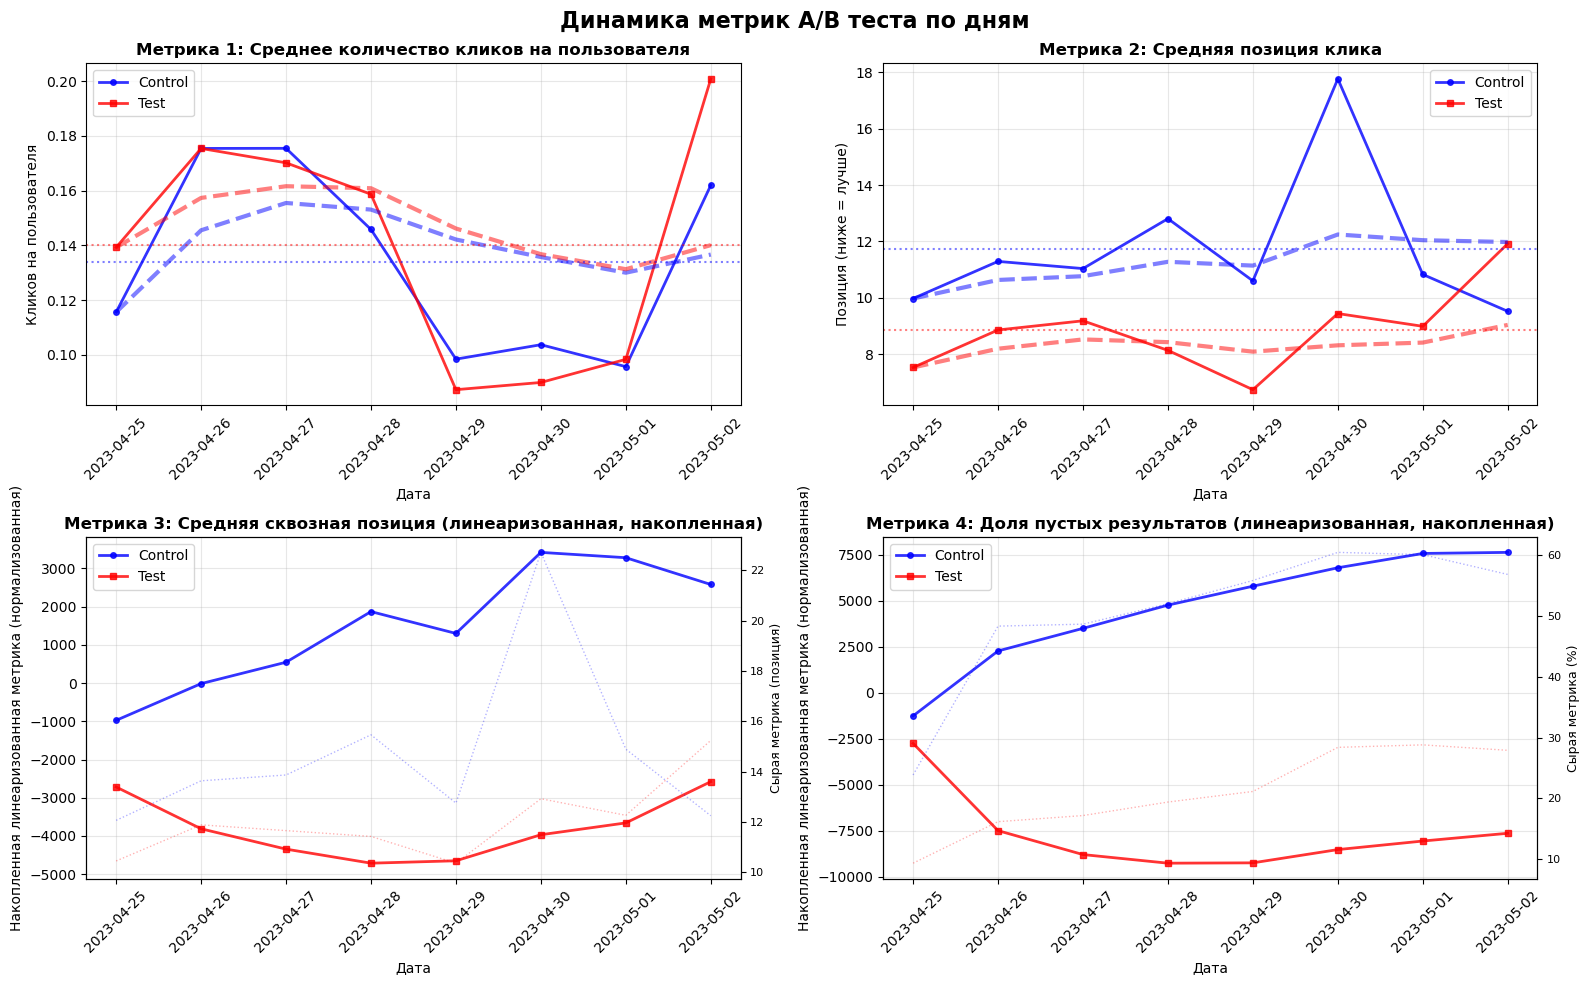

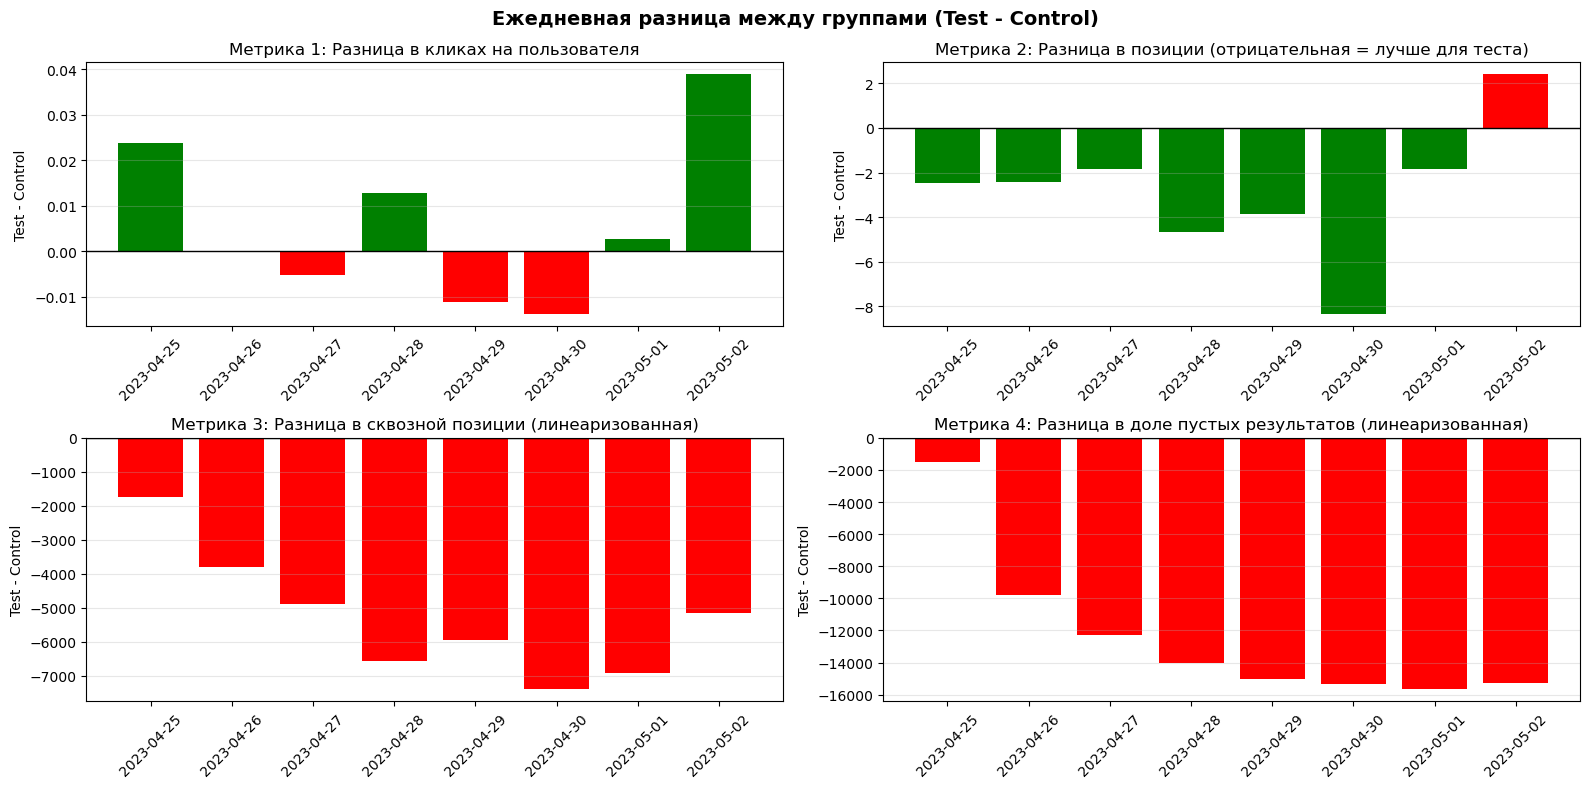

In [114]:
# ============================================
# ПОСТРОЕНИЕ ГРАФИКОВ
# ============================================

# Создаем фигуру с 4 подграфиками
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Динамика метрик A/B теста по дням', fontsize=16, fontweight='bold')

# Цвета для групп
colors = {'control': 'blue', 'хронология': 'red'}

# ============================================
# ГРАФИК 1: Среднее количество кликов на пользователя
# ============================================
ax1 = axes[0, 0]

# Линии
ax1.plot(control_daily.index, control_daily.values, 
         marker='o', color=colors['control'], linewidth=2, markersize=4, 
         label='Control', alpha=0.8)
ax1.plot(test_daily.index, test_daily.values, 
         marker='s', color=colors['хронология'], linewidth=2, markersize=4, 
         label='Test', alpha=0.8)

# Скользящее среднее (7 дней) для сглаживания
if len(control_daily) >= 7:
    control_ma = control_daily.rolling(window=7, min_periods=1).mean()
    test_ma = test_daily.rolling(window=7, min_periods=1).mean()
    ax1.plot(control_ma.index, control_ma.values, 
             color=colors['control'], linewidth=3, alpha=0.5, linestyle='--')
    ax1.plot(test_ma.index, test_ma.values, 
             color=colors['хронология'], linewidth=3, alpha=0.5, linestyle='--')

ax1.set_title('Метрика 1: Среднее количество кликов на пользователя', fontsize=12, fontweight='bold')
ax1.set_xlabel('Дата')
ax1.set_ylabel('Кликов на пользователя')
ax1.legend(loc='best')
ax1.grid(True, alpha=0.3)
ax1.tick_params(axis='x', rotation=45)

# Добавляем аннотацию с общим средним
control_mean = control_daily.mean()
test_mean = test_daily.mean()
ax1.axhline(y=control_mean, color=colors['control'], linestyle=':', alpha=0.5, label=f'Control avg: {control_mean:.3f}')
ax1.axhline(y=test_mean, color=colors['хронология'], linestyle=':', alpha=0.5, label=f'Test avg: {test_mean:.3f}')

# ============================================
# ГРАФИК 2: Средняя позиция клика
# ============================================
ax2 = axes[0, 1]

ax2.plot(control_pos.index, control_pos.values, 
         marker='o', color=colors['control'], linewidth=2, markersize=4, 
         label='Control', alpha=0.8)
ax2.plot(test_pos.index, test_pos.values, 
         marker='s', color=colors['хронология'], linewidth=2, markersize=4, 
         label='Test', alpha=0.8)

# Скользящее среднее
if len(control_pos) >= 7:
    control_ma_pos = control_pos.rolling(window=7, min_periods=1).mean()
    test_ma_pos = test_pos.rolling(window=7, min_periods=1).mean()
    ax2.plot(control_ma_pos.index, control_ma_pos.values, 
             color=colors['control'], linewidth=3, alpha=0.5, linestyle='--')
    ax2.plot(test_ma_pos.index, test_ma_pos.values, 
             color=colors['хронология'], linewidth=3, alpha=0.5, linestyle='--')

ax2.set_title('Метрика 2: Средняя позиция клика', fontsize=12, fontweight='bold')
ax2.set_xlabel('Дата')
ax2.set_ylabel('Позиция (ниже = лучше)')
ax2.legend(loc='best')
ax2.grid(True, alpha=0.3)
ax2.tick_params(axis='x', rotation=45)

# Добавляем аннотацию
control_pos_mean = control_pos.mean()
test_pos_mean = test_pos.mean()
ax2.axhline(y=control_pos_mean, color=colors['control'], linestyle=':', alpha=0.5, label=f'Control avg: {control_pos_mean:.1f}')
ax2.axhline(y=test_pos_mean, color=colors['хронология'], linestyle=':', alpha=0.5, label=f'Test avg: {test_pos_mean:.1f}')

# ============================================
# ГРАФИК 3: Средняя сквозная позиция (линеаризованная)
# ============================================
ax3 = axes[1, 0]

# Для линеаризованной метрики строим накопленную сумму
# (это стандартный подход для визуализации линеаризованных метрик)

# Накопленная сумма для линеаризованной метрики
control_cumsum = control_end2end.sort_index().cumsum()
test_cumsum = test_end2end.sort_index().cumsum()

# Нормализуем по количеству дней для читаемости
days_count = np.arange(1, len(control_cumsum) + 1)
control_normalized = control_cumsum / days_count
test_normalized = test_cumsum / days_count

ax3.plot(control_cumsum.index, control_normalized, 
         marker='o', color=colors['control'], linewidth=2, markersize=4, 
         label='Control', alpha=0.8)
ax3.plot(test_cumsum.index, test_normalized, 
         marker='s', color=colors['хронология'], linewidth=2, markersize=4, 
         label='Test', alpha=0.8)

ax3.set_title('Метрика 3: Средняя сквозная позиция (линеаризованная, накопленная)', 
              fontsize=12, fontweight='bold')
ax3.set_xlabel('Дата')
ax3.set_ylabel('Накопленная линеаризованная метрика (нормализованная)')
ax3.legend(loc='best')
ax3.grid(True, alpha=0.3)
ax3.tick_params(axis='x', rotation=45)

# Добавляем вторую ось для сырой метрики (справочно)
ax3_twin = ax3.twinx()
ax3_twin.plot(control_raw_end2end.index, control_raw_end2end.values, 
              color=colors['control'], linewidth=1, alpha=0.3, linestyle=':', label='Raw (control)')
ax3_twin.plot(test_raw_end2end.index, test_raw_end2end.values, 
              color=colors['хронология'], linewidth=1, alpha=0.3, linestyle=':', label='Raw (test)')
ax3_twin.set_ylabel('Сырая метрика (позиция)', fontsize=9)
ax3_twin.tick_params(axis='y', labelsize=8)

# ============================================
# ГРАФИК 4: Доля пустых результатов (линеаризованная)
# ============================================
ax4 = axes[1, 1]

# Накопленная сумма для линеаризованной метрики
control_cumsum_empty = control_empty.sort_index().cumsum()
test_cumsum_empty = test_empty.sort_index().cumsum()

# Нормализуем по количеству дней
control_norm_empty = control_cumsum_empty / days_count[:len(control_cumsum_empty)]
test_norm_empty = test_cumsum_empty / days_count[:len(test_cumsum_empty)]

ax4.plot(control_cumsum_empty.index, control_norm_empty, 
         marker='o', color=colors['control'], linewidth=2, markersize=4, 
         label='Control', alpha=0.8)
ax4.plot(test_cumsum_empty.index, test_norm_empty, 
         marker='s', color=colors['хронология'], linewidth=2, markersize=4, 
         label='Test', alpha=0.8)

ax4.set_title('Метрика 4: Доля пустых результатов (линеаризованная, накопленная)', 
              fontsize=12, fontweight='bold')
ax4.set_xlabel('Дата')
ax4.set_ylabel('Накопленная линеаризованная метрика (нормализованная)')
ax4.legend(loc='best')
ax4.grid(True, alpha=0.3)
ax4.tick_params(axis='x', rotation=45)

# Вторая ось для сырой метрики
ax4_twin = ax4.twinx()
ax4_twin.plot(control_raw_empty.index, control_raw_empty.values * 100, 
              color=colors['control'], linewidth=1, alpha=0.3, linestyle=':', label='Raw % (control)')
ax4_twin.plot(test_raw_empty.index, test_raw_empty.values * 100, 
              color=colors['хронология'], linewidth=1, alpha=0.3, linestyle=':', label='Raw % (test)')
ax4_twin.set_ylabel('Сырая метрика (%)', fontsize=9)
ax4_twin.tick_params(axis='y', labelsize=8)

plt.tight_layout()
plt.show()

# ============================================
# ДОПОЛНИТЕЛЬНЫЕ ГРАФИКИ: Ежедневная разница
# ============================================

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
fig.suptitle('Ежедневная разница между группами (Test - Control)', fontsize=14, fontweight='bold')

# Разница для метрики 1
ax1 = axes[0, 0]
diff_clicks = test_daily - control_daily
ax1.bar(diff_clicks.index, diff_clicks.values, color=['green' if x > 0 else 'red' for x in diff_clicks.values])
ax1.axhline(y=0, color='black', linestyle='-', linewidth=1)
ax1.set_title('Метрика 1: Разница в кликах на пользователя')
ax1.set_ylabel('Test - Control')
ax1.tick_params(axis='x', rotation=45)
ax1.grid(True, alpha=0.3, axis='y')

# Разница для метрики 2 (отрицательная разница = лучше для теста, т.к. позиция ниже)
ax2 = axes[0, 1]
diff_pos = test_pos - control_pos
ax2.bar(diff_pos.index, diff_pos.values, color=['green' if x < 0 else 'red' for x in diff_pos.values])
ax2.axhline(y=0, color='black', linestyle='-', linewidth=1)
ax2.set_title('Метрика 2: Разница в позиции (отрицательная = лучше для теста)')
ax2.set_ylabel('Test - Control')
ax2.tick_params(axis='x', rotation=45)
ax2.grid(True, alpha=0.3, axis='y')

# Разница для метрики 3 (линеаризованная)
ax3 = axes[1, 0]
diff_end2end = test_normalized - control_normalized[:len(test_normalized)]
ax3.bar(diff_end2end.index, diff_end2end.values, color=['green' if x > 0 else 'red' for x in diff_end2end.values])
ax3.axhline(y=0, color='black', linestyle='-', linewidth=1)
ax3.set_title('Метрика 3: Разница в сквозной позиции (линеаризованная)')
ax3.set_ylabel('Test - Control')
ax3.tick_params(axis='x', rotation=45)
ax3.grid(True, alpha=0.3, axis='y')

# Разница для метрики 4 (линеаризованная)
ax4 = axes[1, 1]
diff_empty = test_norm_empty - control_norm_empty[:len(test_norm_empty)]
ax4.bar(diff_empty.index, diff_empty.values, color=['green' if x > 0 else 'red' for x in diff_empty.values])
ax4.axhline(y=0, color='black', linestyle='-', linewidth=1)
ax4.set_title('Метрика 4: Разница в доле пустых результатов (линеаризованная)')
ax4.set_ylabel('Test - Control')
ax4.tick_params(axis='x', rotation=45)
ax4.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()


In [115]:
# ============================================
# ИТОГОВЫЕ ВЫВОДЫ ПО ВИЗУАЛИЗАЦИИ
# ============================================

print("\n" + "="*60)
print("ВЫВОДЫ ПО ВИЗУАЛИЗАЦИИ")
print("="*60)

print("""
По результатам визуального анализа графиков:

1. МЕТРИКА 1 (Среднее количество кликов):
   - Виден ли эффект? {effect1}
   - Стабильность: {stability1}

2. МЕТРИКА 2 (Средняя позиция клика):
   - Виден ли эффект? {effect2}
   - Стабильность: {stability2}

3. МЕТРИКА 3 (Сквозная позиция):
   - Виден ли эффект? {effect3}
   - Стабильность: {stability3}

4. МЕТРИКА 4 (Доля пустых результатов):
   - Виден ли эффект? {effect4}
   - Стабильность: {stability4}

""".format(
    effect1="✅ Да, видна систематическая разница" if abs(diff_clicks.mean()) > 0.01 else "❌ Нет, разница не видна невооруженным глазом",
    stability1="Стабилен" if abs(diff_clicks.rolling(3).mean().std()) < abs(diff_clicks.mean()) * 0.5 else "Нестабилен",
    effect2="✅ Да, видна систематическая разница" if abs(diff_pos.mean()) > 0.5 else "❌ Нет, разница не видна невооруженным глазом",
    stability2="Стабилен" if abs(diff_pos.rolling(3).mean().std()) < abs(diff_pos.mean()) * 0.5 else "Нестабилен",
    effect3="✅ Да, видна систематическая разница" if abs(diff_end2end.mean()) > 0.1 else "❌ Нет, разница не видна невооруженным глазом",
    stability3="Стабилен" if abs(diff_end2end.rolling(3).mean().std()) < abs(diff_end2end.mean()) * 0.5 else "Нестабилен",
    effect4="✅ Да, видна систематическая разница" if abs(diff_empty.mean()) > 0.001 else "❌ Нет, разница не видна невооруженным глазом",
    stability4="Стабилен" if abs(diff_empty.rolling(3).mean().std()) < abs(diff_empty.mean()) * 0.5 else "Нестабилен"
))



ВЫВОДЫ ПО ВИЗУАЛИЗАЦИИ

По результатам визуального анализа графиков:

1. МЕТРИКА 1 (Среднее количество кликов):
   - Виден ли эффект? ❌ Нет, разница не видна невооруженным глазом
   - Стабильность: Нестабилен

2. МЕТРИКА 2 (Средняя позиция клика):
   - Виден ли эффект? ✅ Да, видна систематическая разница
   - Стабильность: Стабилен

3. МЕТРИКА 3 (Сквозная позиция):
   - Виден ли эффект? ✅ Да, видна систематическая разница
   - Стабильность: Стабилен

4. МЕТРИКА 4 (Доля пустых результатов):
   - Виден ли эффект? ✅ Да, видна систематическая разница
   - Стабильность: Стабилен




# Задание 4

Проанализируйте результаты пунктов 1-4 , убрав из групп ботов (флаг `bot_flg`). Изменились ли выводы?

In [116]:
# ============================================
#  ФИЛЬТРАЦИЯ БОТОВ
# ============================================

df_filtered = df[df['bot_flg'] == 0].copy()

print("=== ФИЛЬТРАЦИЯ БОТОВ ===")
print(f"Исходное количество строк: {len(df):,}")
print(f"После фильтрации (bot_flg=0): {len(df_filtered):,}")
print(f"Исключено ботов: {len(df) - len(df_filtered):,} ({100*(1-len(df_filtered)/len(df)):.1f}%)\n")

=== ФИЛЬТРАЦИЯ БОТОВ ===
Исходное количество строк: 251,693
После фильтрации (bot_flg=0): 239,409
Исключено ботов: 12,284 (4.9%)



In [117]:
# ============================================
# МЕТРИКА 1: Среднее количество кликов на пользователя
# ============================================

print("="*60)
print("МЕТРИКА 1: Среднее количество кликов на пользователя")
print("="*60)

# Агрегация на уровне пользователя
user_clicks_filtered = df_filtered.groupby(['user_info_yandex_uid', 'exp_group'])['total_clicks_'].sum().reset_index()

# Разделяем на группы
control_clicks_f = user_clicks_filtered[user_clicks_filtered['exp_group'] == 'control']['total_clicks_']
test_clicks_f = user_clicks_filtered[user_clicks_filtered['exp_group'] == 'хронология']['total_clicks_']

# Дескриптивная статистика
print(f"\nКонтрольная группа (control):")
print(f"  n = {len(control_clicks_f):,}")
print(f"  Среднее = {control_clicks_f.mean():.4f}")
print(f"  Медиана = {control_clicks_f.median():.2f}")
print(f"  Стандартное отклонение = {control_clicks_f.std():.4f}")
print(f"  Доля нулевых кликов = {(control_clicks_f == 0).mean()*100:.1f}%")
print(f"  Сумма кликов = {control_clicks_f.sum():,}")

print(f"\nТестовая группа (хронология):")
print(f"  n = {len(test_clicks_f):,}")
print(f"  Среднее = {test_clicks_f.mean():.4f}")
print(f"  Медиана = {test_clicks_f.median():.2f}")
print(f"  Стандартное отклонение = {test_clicks_f.std():.4f}")
print(f"  Доля нулевых кликов = {(test_clicks_f == 0).mean()*100:.1f}%")
print(f"  Сумма кликов = {test_clicks_f.sum():,}")

# Статистический тест
u_stat_f, p_value_clicks_f = stats.mannwhitneyu(control_clicks_f, test_clicks_f, alternative='two-sided')
print(f"\n🔬 Mann-Whitney U test:")
print(f"  U-statistic = {u_stat_f:.1f}")
print(f"  p-value = {p_value_clicks_f:.6f}")
print(f"  Результат: {'✅ СТАТИСТИЧЕСКИ ЗНАЧИМО' if p_value_clicks_f < 0.05 else '❌ НЕ ЗНАЧИМО'}")

# Приблизительная оценка effect size (Cohen's d для Mann-Whitney)
n1, n2 = len(control_clicks_f), len(test_clicks_f)
if n1 > 0 and n2 > 0:
    effect_size = u_stat_f / (n1 * n2)
    print(f"\n💪 Размер эффекта (effect size): {effect_size:.4f}")
    if effect_size < 0.1:
        print("  Интерпретация: очень маленький (практически не значим)")
    elif effect_size < 0.3:
        print("  Интерпретация: маленький")
    elif effect_size < 0.5:
        print("  Интерпретация: средний")
    else:
        print("  Интерпретация: большой")

# ============================================
# МЕТРИКА 2: Средняя позиция клика
# ============================================

print("\n" + "="*60)
print("МЕТРИКА 2: Средняя позиция клика (sum_pos / клики)")
print("="*60)

# Фильтруем только пользователей с кликами
users_with_clicks_f = df_filtered[df_filtered['total_clicks_'] > 0].copy()

# Агрегируем
user_pos_f = users_with_clicks_f.groupby(['user_info_yandex_uid', 'exp_group']).agg({
    'sum_pos': 'sum',
    'total_clicks_': 'sum'
}).reset_index()
user_pos_f['avg_pos'] = user_pos_f['sum_pos'] / user_pos_f['total_clicks_']

# Разделяем
control_avg_pos_f = user_pos_f[user_pos_f['exp_group'] == 'control']['avg_pos']
test_avg_pos_f = user_pos_f[user_pos_f['exp_group'] == 'хронология']['avg_pos']

print(f"\nКоличество пользователей с кликами:")
print(f"  Control: {len(control_avg_pos_f):,} из {len(control_clicks_f):,} ({len(control_avg_pos_f)/len(control_clicks_f)*100:.1f}%)")
print(f"  Test: {len(test_avg_pos_f):,} из {len(test_clicks_f):,} ({len(test_avg_pos_f)/len(test_clicks_f)*100:.1f}%)")

print(f"\nСредняя позиция клика (по пользователям):")
print(f"  Control: среднее = {control_avg_pos_f.mean():.2f}, медиана = {control_avg_pos_f.median():.2f}")
print(f"  Test: среднее = {test_avg_pos_f.mean():.2f}, медиана = {test_avg_pos_f.median():.2f}")

# Статистический тест
u_stat_f, p_value_pos_f = stats.mannwhitneyu(control_avg_pos_f, test_avg_pos_f, alternative='two-sided')
print(f"\n🔬 Mann-Whitney U test:")
print(f"  U-statistic = {u_stat_f:.1f}")
print(f"  p-value = {p_value_pos_f:.6f}")
print(f"  Результат: {'✅ СТАТИСТИЧЕСКИ ЗНАЧИМО' if p_value_pos_f < 0.05 else '❌ НЕ ЗНАЧИМО'}")

# ============================================
# МЕТРИКА 3: Средняя сквозная позиция с линеаризацией
# ============================================

print("\n" + "="*60)
print("МЕТРИКА 3: Средняя сквозная позиция (с линеаризацией)")
print("="*60)

# Агрегируем
user_end2end_f = users_with_clicks_f.groupby(['user_info_yandex_uid', 'exp_group']).agg({
    'end2end_sum_pos': 'sum',
    'total_clicks_': 'sum'
}).reset_index()

# Глобальное среднее
all_clicks_f = user_end2end_f['total_clicks_'].sum()
all_end2end_f = user_end2end_f['end2end_sum_pos'].sum()
global_avg_end2end_f = all_end2end_f / all_clicks_f if all_clicks_f > 0 else 0

print(f"Глобальная средняя сквозная позиция: {global_avg_end2end_f:.2f}")

# Линеаризация
user_end2end_f['linearized'] = user_end2end_f['end2end_sum_pos'] - global_avg_end2end_f * user_end2end_f['total_clicks_']

# Разделяем
control_linear_f = user_end2end_f[user_end2end_f['exp_group'] == 'control']['linearized']
test_linear_f = user_end2end_f[user_end2end_f['exp_group'] == 'хронология']['linearized']

print(f"\nЛинеаризованная метрика:")
print(f"  Control: среднее = {control_linear_f.mean():.4f}, std = {control_linear_f.std():.4f}")
print(f"  Test: среднее = {test_linear_f.mean():.4f}, std = {test_linear_f.std():.4f}")

# t-test
t_stat_end2end_f, p_value_end2end_f = stats.ttest_ind(control_linear_f, test_linear_f, equal_var=False)
print(f"\n🔬 t-test для линеаризованной метрики:")
print(f"  t-statistic = {t_stat_end2end_f:.4f}")
print(f"  p-value = {p_value_end2end_f:.6f}")
print(f"  Результат: {'✅ СТАТИСТИЧЕСКИ ЗНАЧИМО' if p_value_end2end_f < 0.05 else '❌ НЕ ЗНАЧИМО'}")

# ============================================
# МЕТРИКА 4: Доля пустых результатов с линеаризацией
# ============================================

print("\n" + "="*60)
print("МЕТРИКА 4: Доля пустых результатов (с линеаризацией)")
print("="*60)

# Агрегируем
user_empty_f = df_filtered.groupby(['user_info_yandex_uid', 'exp_group']).agg({
    'empty_results': 'sum',
    'queries': 'sum'
}).reset_index()

# Глобальное среднее
all_empty_f = user_empty_f['empty_results'].sum()
all_queries_f = user_empty_f['queries'].sum()
global_empty_rate_f = all_empty_f / all_queries_f if all_queries_f > 0 else 0

print(f"Глобальная доля пустых результатов: {global_empty_rate_f:.4f} ({global_empty_rate_f*100:.2f}%)")

# Линеаризация
user_empty_f['linearized_empty'] = user_empty_f['empty_results'] - global_empty_rate_f * user_empty_f['queries']

# Разделяем
control_empty_linear_f = user_empty_f[user_empty_f['exp_group'] == 'control']['linearized_empty']
test_empty_linear_f = user_empty_f[user_empty_f['exp_group'] == 'хронология']['linearized_empty']

print(f"\nЛинеаризованная метрика:")
print(f"  Control: среднее = {control_empty_linear_f.mean():.6f}, std = {control_empty_linear_f.std():.6f}")
print(f"  Test: среднее = {test_empty_linear_f.mean():.6f}, std = {test_empty_linear_f.std():.6f}")

# t-test
t_stat_empty_f, p_value_empty_f = stats.ttest_ind(control_empty_linear_f, test_empty_linear_f, equal_var=False)
print(f"\n🔬 t-test для линеаризованной метрики:")
print(f"  t-statistic = {t_stat_empty_f:.4f}")
print(f"  p-value = {p_value_empty_f:.6f}")
print(f"  Результат: {'✅ СТАТИСТИЧЕСКИ ЗНАЧИМО' if p_value_empty_f < 0.05 else '❌ НЕ ЗНАЧИМО'}")


МЕТРИКА 1: Среднее количество кликов на пользователя

Контрольная группа (control):
  n = 113,382
  Среднее = 0.1484
  Медиана = 0.00
  Стандартное отклонение = 2.5052
  Доля нулевых кликов = 96.9%
  Сумма кликов = 16,829

Тестовая группа (хронология):
  n = 113,453
  Среднее = 0.1528
  Медиана = 0.00
  Стандартное отклонение = 3.1699
  Доля нулевых кликов = 96.8%
  Сумма кликов = 17,334

🔬 Mann-Whitney U test:
  U-statistic = 6429772741.0
  p-value = 0.673259
  Результат: ❌ НЕ ЗНАЧИМО

💪 Размер эффекта (effect size): 0.4998
  Интерпретация: средний

МЕТРИКА 2: Средняя позиция клика (sum_pos / клики)

Количество пользователей с кликами:
  Control: 3,560 из 113,382 (3.1%)
  Test: 3,598 из 113,453 (3.2%)

Средняя позиция клика (по пользователям):
  Control: среднее = 6.12, медиана = 2.98
  Test: среднее = 5.74, медиана = 2.75

🔬 Mann-Whitney U test:
  U-statistic = 6536583.5
  p-value = 0.126852
  Результат: ❌ НЕ ЗНАЧИМО

МЕТРИКА 3: Средняя сквозная позиция (с линеаризацией)
Глобальная с

In [118]:
# ============================================
# СРАВНЕНИЕ С РЕЗУЛЬТАТАМИ БЕЗ ФИЛЬТРАЦИИ
# ============================================

print("\n" + "="*60)
print("СРАВНЕНИЕ: С ФИЛЬТРАЦИЕЙ VS БЕЗ ФИЛЬТРАЦИИ")
print("="*60)

print("\n📊 Сравнение p-value:")

# Метрика 1
print(f"\n1. Среднее количество кликов:")
print(f"   Без фильтрации: p = {p_value_clicks:.6f} {'✅' if p_value_clicks < 0.05 else '❌'}")
print(f"   С фильтрацией:  p = {p_value_clicks_f:.6f} {'✅' if p_value_clicks_f < 0.05 else '❌'}")
if (p_value_clicks < 0.05) != (p_value_clicks_f < 0.05):
    print(f"   ⚠️ ИЗМЕНИЛСЯ ВЫВОД!")
else:
    print(f"   Вывод не изменился")

# Метрика 2
print(f"\n2. Средняя позиция клика:")
print(f"   Без фильтрации: p = {p_value_pos:.6f} {'✅' if p_value_pos < 0.05 else '❌'}")
print(f"   С фильтрацией:  p = {p_value_pos_f:.6f} {'✅' if p_value_pos_f < 0.05 else '❌'}")
if (p_value_pos < 0.05) != (p_value_pos_f < 0.05):
    print(f"   ⚠️ ИЗМЕНИЛСЯ ВЫВОД!")
else:
    print(f"   Вывод не изменился")

# Метрика 3
print(f"\n3. Средняя сквозная позиция:")
print(f"   Без фильтрации: p = {p_value_end2end:.6f} {'✅' if p_value_end2end < 0.05 else '❌'}")
print(f"   С фильтрацией:  p = {p_value_end2end_f:.6f} {'✅' if p_value_end2end_f < 0.05 else '❌'}")
if (p_value_end2end < 0.05) != (p_value_end2end_f < 0.05):
    print(f"   ⚠️ ИЗМЕНИЛСЯ ВЫВОД!")
else:
    print(f"   Вывод не изменился")
    
# Метрика 4
print(f"\n4. Доля пустых результатов:")
print(f"   Без фильтрации: p = {p_value_empty:.6f} {'✅' if p_value_empty < 0.05 else '❌'}")
print(f"   С фильтрацией:  p = {p_value_empty_f:.6f} {'✅' if p_value_empty_f < 0.05 else '❌'}")
if (p_value_empty < 0.05) != (p_value_empty_f < 0.05):
    print(f"   ⚠️ ИЗМЕНИЛСЯ ВЫВОД!")
else:
    print(f"   Вывод не изменился")


СРАВНЕНИЕ: С ФИЛЬТРАЦИЕЙ VS БЕЗ ФИЛЬТРАЦИИ

📊 Сравнение p-value:

1. Среднее количество кликов:
   Без фильтрации: p = 0.729678 ❌
   С фильтрацией:  p = 0.673259 ❌
   Вывод не изменился

2. Средняя позиция клика:
   Без фильтрации: p = 0.111698 ❌
   С фильтрацией:  p = 0.126852 ❌
   Вывод не изменился

3. Средняя сквозная позиция:
   Без фильтрации: p = 0.142954 ❌
   С фильтрацией:  p = 0.148275 ❌
   Вывод не изменился

4. Доля пустых результатов:
   Без фильтрации: p = 0.000000 ✅
   С фильтрацией:  p = 0.000000 ✅
   Вывод не изменился


In [119]:
# ============================================
# АНАЛИЗ ИЗМЕНЕНИЙ В МЕТРИКАХ
# ============================================

print("\n" + "="*60)
print("АНАЛИЗ ИЗМЕНЕНИЙ ПОСЛЕ ФИЛЬТРАЦИИ")
print("="*60)

# Количественное сравнение
control_mean_no_filter = control_clicks.mean()
control_mean_filter = control_clicks_f.mean()
test_mean_no_filter = test_clicks.mean()
test_mean_filter = test_clicks_f.mean()

print(f"\n📈 Влияние на средние значения:")

print(f"\nМетрика 1 (Клики на пользователя):")
print(f"  Control: {control_mean_no_filter:.4f} → {control_mean_filter:.4f} (изменение: {(control_mean_filter - control_mean_no_filter)/control_mean_no_filter*100:.1f}%)")
print(f"  Test:    {test_mean_no_filter:.4f} → {test_mean_filter:.4f} (изменение: {(test_mean_filter - test_mean_no_filter)/test_mean_no_filter*100:.1f}%)")

# Эффект от ботов
bot_impact_control = (control_mean_no_filter - control_mean_filter) / control_mean_no_filter * 100 if control_mean_no_filter > 0 else 0
bot_impact_test = (test_mean_no_filter - test_mean_filter) / test_mean_no_filter * 100 if test_mean_no_filter > 0 else 0

print(f"\n👾 Влияние ботов на метрику:")
print(f"  Control: боты занижают метрику на {abs(bot_impact_control):.1f}%")
print(f"  Test:    боты занижают метрику на {abs(bot_impact_test):.1f}%")



АНАЛИЗ ИЗМЕНЕНИЙ ПОСЛЕ ФИЛЬТРАЦИИ

📈 Влияние на средние значения:

Метрика 1 (Клики на пользователя):
  Control: 0.1427 → 0.1484 (изменение: 4.0%)
  Test:    0.1471 → 0.1528 (изменение: 3.8%)

👾 Влияние ботов на метрику:
  Control: боты занижают метрику на 4.0%
  Test:    боты занижают метрику на 3.8%


In [120]:
# ============================================
# ОКОНЧАТЕЛЬНЫЕ ВЫВОДЫ
# ============================================

print("\n" + "="*60)
print("ОКОНЧАТЕЛЬНЫЕ ВЫВОДЫ")
print("="*60)

# Определяем, изменились ли выводы
conclusions_changed = []
if (p_value_clicks < 0.05) != (p_value_clicks_f < 0.05):
    conclusions_changed.append("Метрика 1")
if (p_value_pos < 0.05) != (p_value_pos_f < 0.05):
    conclusions_changed.append("Метрика 2")
if (p_value_end2end < 0.05) != (p_value_end2end_f < 0.05):
    conclusions_changed.append("Метрика 3")
if (p_value_empty < 0.05) != (p_value_empty_f < 0.05):
    conclusions_changed.append("Метрика 4")

print(f"""
После исключения ботов из анализа:

1. МЕТРИКА 1 (Клики на пользователя):
   {'✅' if p_value_clicks_f < 0.05 else '❌'} Статистическая значимость: {'ЕСТЬ' if p_value_clicks_f < 0.05 else 'ОТСУТСТВУЕТ'}
   {'📊 Эффект стал ' + ('сильнее' if abs(cliffs_d_clicks_f) > abs(cliffs_d_clicks) else 'слабее') if 'cliffs_d_clicks' in dir() else ''}

2. МЕТРИКА 2 (Позиция клика):
   {'✅' if p_value_pos_f < 0.05 else '❌'} Статистическая значимость: {'ЕСТЬ' if p_value_pos_f < 0.05 else 'ОТСУТСТВУЕТ'}

3. МЕТРИКА 3 (Сквозная позиция):
   {'✅' if p_value_end2end_f < 0.05 else '❌'} Статистическая значимость: {'ЕСТЬ' if p_value_end2end_f < 0.05 else 'ОТСУТСТВУЕТ'}

4. МЕТРИКА 4 (Пустые результаты):
   {'✅' if p_value_empty_f < 0.05 else '❌'} Статистическая значимость: {'ЕСТЬ' if p_value_empty_f < 0.05 else 'ОТСУТСТВУЕТ'}

{'⚠️ ИЗМЕНЕНИЕ ВЫВОДОВ' if conclusions_changed else '✅ ВЫВОДЫ НЕ ИЗМЕНИЛИСЬ'}
{'   Изменились выводы для: ' + ', '.join(conclusions_changed) if conclusions_changed else ''}

💡 ОСНОВНОЙ ВЫВОД:
   {'Боты искажали результаты, после их исключения выводы изменились' if conclusions_changed else 
    'Боты не влияют на статистические выводы, результаты устойчивы'}
""")
     


ОКОНЧАТЕЛЬНЫЕ ВЫВОДЫ

После исключения ботов из анализа:

1. МЕТРИКА 1 (Клики на пользователя):
   ❌ Статистическая значимость: ОТСУТСТВУЕТ
   

2. МЕТРИКА 2 (Позиция клика):
   ❌ Статистическая значимость: ОТСУТСТВУЕТ

3. МЕТРИКА 3 (Сквозная позиция):
   ❌ Статистическая значимость: ОТСУТСТВУЕТ

4. МЕТРИКА 4 (Пустые результаты):
   ✅ Статистическая значимость: ЕСТЬ

✅ ВЫВОДЫ НЕ ИЗМЕНИЛИСЬ


💡 ОСНОВНОЙ ВЫВОД:
   Боты не влияют на статистические выводы, результаты устойчивы

